In [2]:
# Import required libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    auc
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
# Load the employee attrition dataset

data = pd.read_csv("employee_attrition_dataset.csv")

# Display the first 5 records
data.head()

,Employee_ID,Age,Years_Experience,Education,Department,Monthly_Salary_INR,Performance_Score,Job_Satisfaction,Overtime,Promotion_Last_2_Years,Attrition
0,EMP001,24,1,Master,Operations,28641,3,5,Yes,Yes,Yes
1,EMP002,51,25,Bachelor,Sales,82799,4,2,No,No,Yes
2,EMP003,47,0,Master,Operations,28134,1,4,Yes,No,Yes
3,EMP004,38,16,Diploma,Operations,76952,2,3,No,No,No
4,EMP005,38,9,Bachelor,Sales,26673,2,1,No,No,Yes


In [4]:
# Check the number of rows and columns

print("Dataset Shape:", data.shape)

# Display column names
print("\nColumn Names:")
print(data.columns.tolist())

# Check dataset information
print("\nDataset Information:")
data.info()

Dataset Shape: (300, 11)

Column Names:
['Employee_ID', 'Age', 'Years_Experience', 'Education', 'Department', 'Monthly_Salary_INR', 'Performance_Score', 'Job_Satisfaction', 'Overtime', 'Promotion_Last_2_Years', 'Attrition']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   Employee_ID             300 non-null    str  
 1   Age                     300 non-null    int64
 2   Years_Experience        300 non-null    int64
 3   Education               300 non-null    str  
 4   Department              300 non-null    str  
 5   Monthly_Salary_INR      300 non-null    int64
 6   Performance_Score       300 non-null    int64
 7   Job_Satisfaction        300 non-null    int64
 8   Overtime                300 non-null    str  
 9   Promotion_Last_2_Years  300 non-null    str  
 10  Attrition               300 non-null    str

In [5]:
# Check missing values in each column

print("Missing Values:")
print(data.isnull().sum())

# Total missing values
print("\nTotal Missing Values:")
print(data.isnull().sum().sum())

Missing Values:
Employee_ID               0
Age                       0
Years_Experience          0
Education                 0
Department                0
Monthly_Salary_INR        0
Performance_Score         0
Job_Satisfaction          0
Overtime                  0
Promotion_Last_2_Years    0
Attrition                 0
dtype: int64

Total Missing Values:
0


In [6]:
# Check duplicate records

print("Total Duplicate Records:")
print(data.duplicated().sum())

Total Duplicate Records:
0


In [7]:
# Statistical summary of numerical columns

data.describe()


,Age,Years_Experience,Monthly_Salary_INR,Performance_Score,Job_Satisfaction
count,300.000000,300.000000,300.000000,300.000000,300.000000
mean,40.480000,9.636667,51627.350000,2.986667,2.983333
std,10.898878,8.878857,25648.698892,1.407038,1.450310
min,21.000000,0.000000,18000.000000,1.000000,1.000000
25%,32.000000,2.000000,32051.500000,2.000000,2.000000
50%,40.000000,7.000000,45556.500000,3.000000,3.000000
75%,49.250000,15.250000,66603.000000,4.000000,4.000000
max,60.000000,33.000000,130467.000000,5.000000,5.000000


Exploratory Data Analysis(EDA)
1. Employee Age Distribution

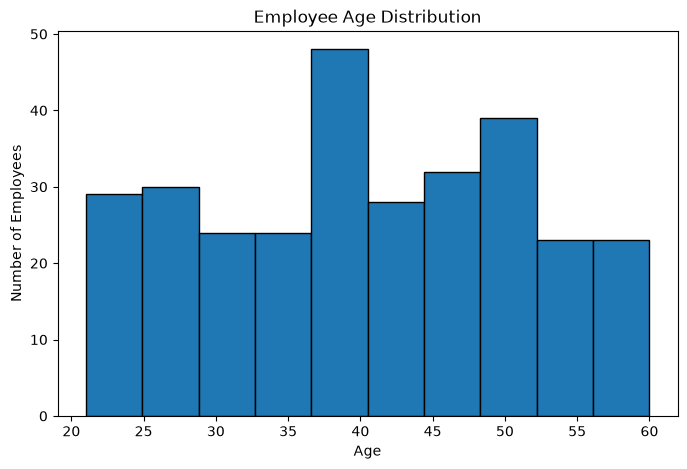

In [8]:

# Employee Age Distribution

plt.figure(figsize=(8, 5))

plt.hist(data['Age'], bins=10, edgecolor='black')

plt.title('Employee Age Distribution')
plt.xlabel('Age')
plt.ylabel('Number of Employees')

plt.show()


2. Employee years of distribution

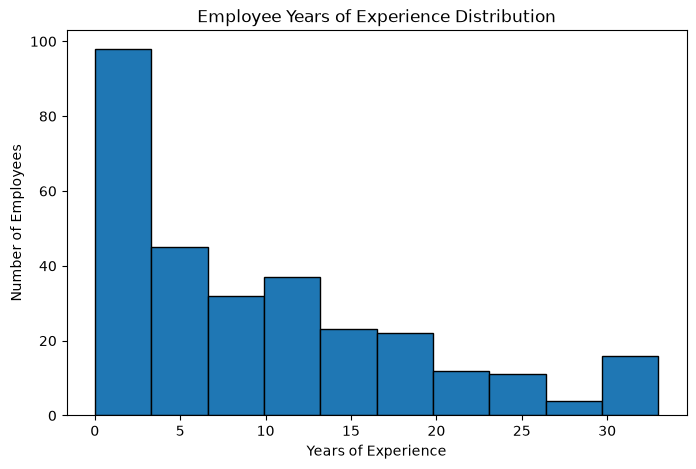

In [9]:
# Years of Experience Distribution

plt.figure(figsize=(8, 5))

plt.hist(data['Years_Experience'], bins=10, edgecolor='black')

plt.title('Employee Years of Experience Distribution')
plt.xlabel('Years of Experience')
plt.ylabel('Number of Employees')

plt.show()

3. Monthly salary distribution

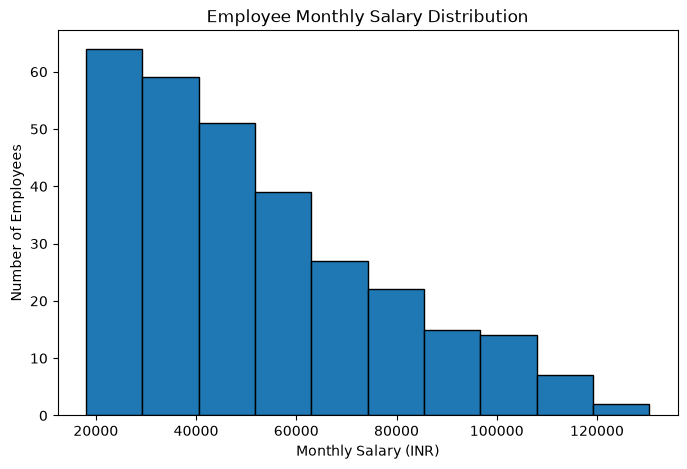

In [10]:
# Monthly Salary Distribution

plt.figure(figsize=(8, 5))

plt.hist(data['Monthly_Salary_INR'], bins=10, edgecolor='black')

plt.title('Employee Monthly Salary Distribution')
plt.xlabel('Monthly Salary (INR)')
plt.ylabel('Number of Employees')

plt.show()

4. Employee performance score distribution

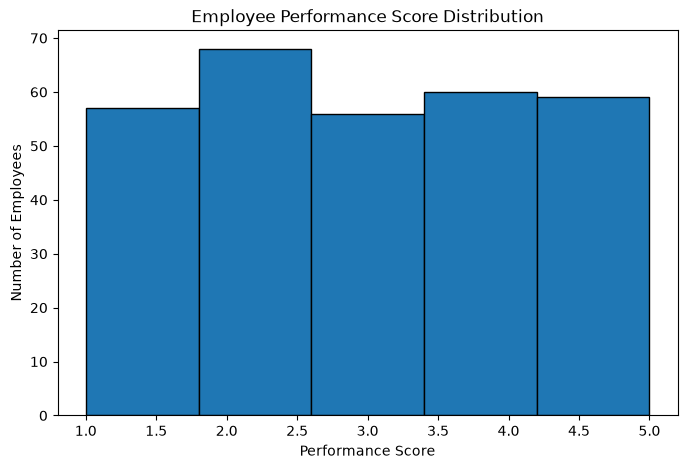

In [11]:
# Employee Performance Score Distribution

plt.figure(figsize=(8, 5))

plt.hist(data['Performance_Score'], bins=5, edgecolor='black')

plt.title('Employee Performance Score Distribution')
plt.xlabel('Performance Score')
plt.ylabel('Number of Employees')

plt.show()

5. Employee education distribution

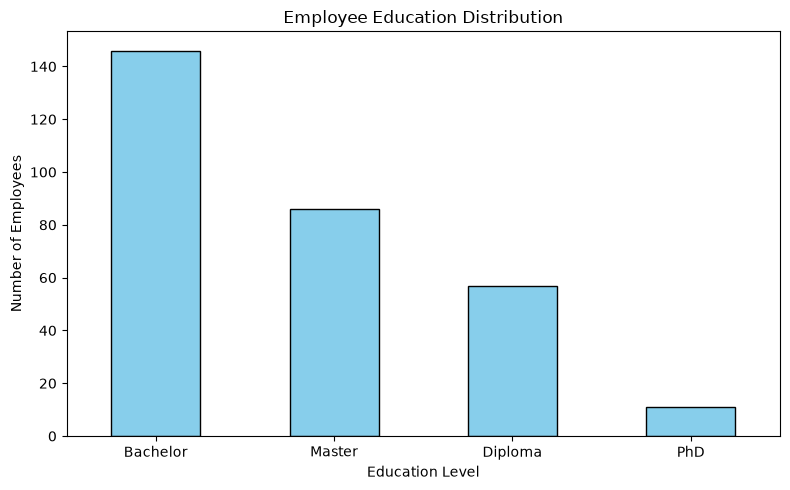

In [12]:
# Employee Education Distribution

plt.figure(figsize=(8, 5))

data['Education'].value_counts().plot(
    kind='bar',
    color='skyblue',
    edgecolor='black'
)

plt.title('Employee Education Distribution')
plt.xlabel('Education Level')
plt.ylabel('Number of Employees')
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

6. Employee department Distribution

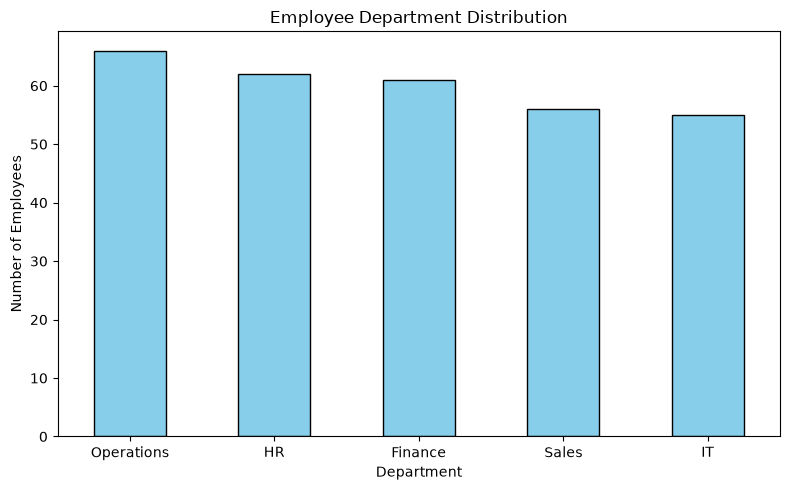

In [13]:
# Employee Department Distribution

plt.figure(figsize=(8, 5))

data['Department'].value_counts().plot(
    kind='bar',
    color='skyblue',
    edgecolor='black'
)

plt.title('Employee Department Distribution')
plt.xlabel('Department')
plt.ylabel('Number of Employees')
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

7. Employee job satisfaction distribution

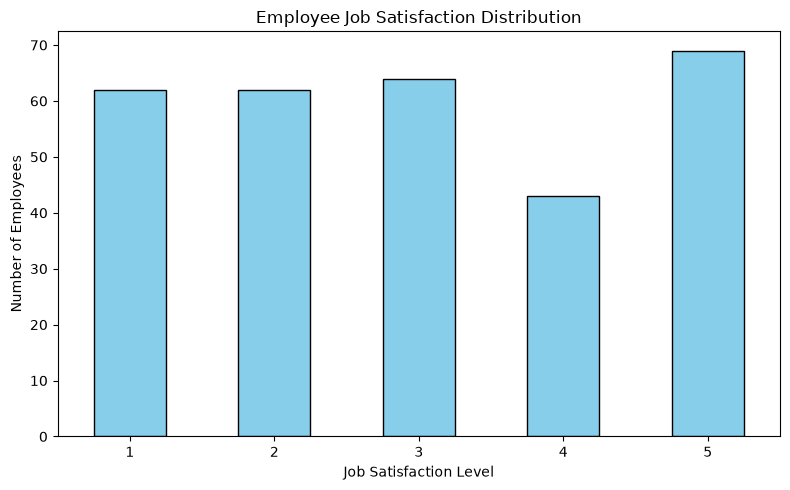

In [14]:
# Employee Job Satisfaction Distribution

plt.figure(figsize=(8, 5))

data['Job_Satisfaction'].value_counts().sort_index().plot(
    kind='bar',
    color='skyblue',
    edgecolor='black'
)

plt.title('Employee Job Satisfaction Distribution')
plt.xlabel('Job Satisfaction Level')
plt.ylabel('Number of Employees')
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

8. Employee overtime distribution

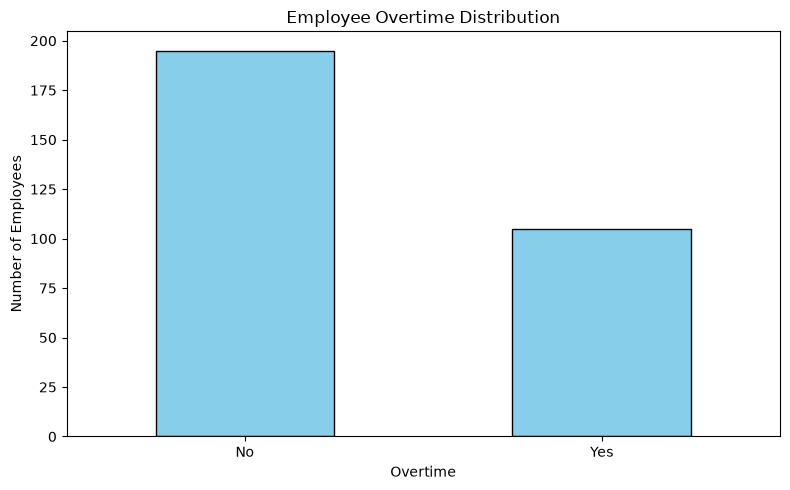

In [15]:
# Employee Overtime Distribution

plt.figure(figsize=(8, 5))

data['Overtime'].value_counts().plot(
    kind='bar',
    color='skyblue',
    edgecolor='black'
)

plt.title('Employee Overtime Distribution')
plt.xlabel('Overtime')
plt.ylabel('Number of Employees')
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

9. Employee promotion distribution (last 2 years)

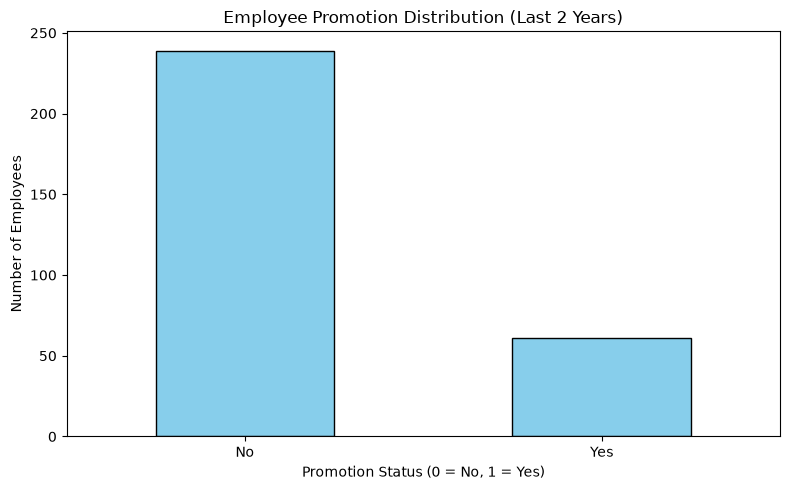

In [16]:
# Employee Promotion Distribution

plt.figure(figsize=(8, 5))

data['Promotion_Last_2_Years'].value_counts().sort_index().plot(
    kind='bar',
    color='skyblue',
    edgecolor='black'
)

plt.title('Employee Promotion Distribution (Last 2 Years)')
plt.xlabel('Promotion Status (0 = No, 1 = Yes)')
plt.ylabel('Number of Employees')
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

10. Employee attribution distribution

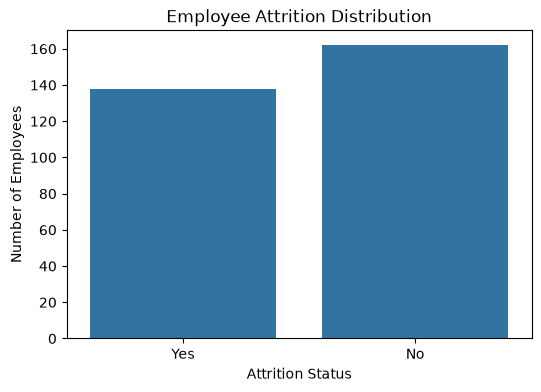

In [17]:
plt.figure(figsize=(6, 4))

sns.countplot(x='Attrition', data=data)

plt.title('Employee Attrition Distribution')
plt.xlabel('Attrition Status')
plt.ylabel('Number of Employees')

plt.show()

11. Department-wise attribution analysis

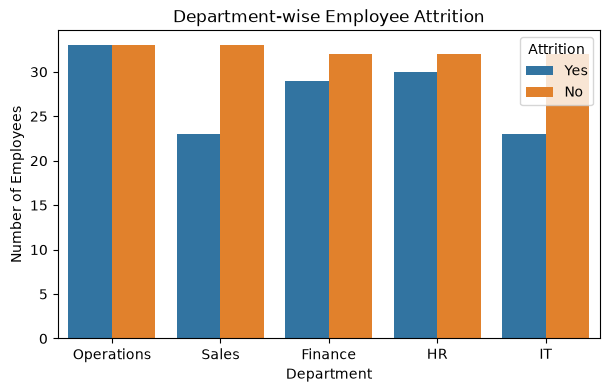

In [18]:
plt.figure(figsize=(7, 4))

sns.countplot(x='Department', hue='Attrition', data=data)

plt.title('Department-wise Employee Attrition')
plt.xlabel('Department')
plt.ylabel('Number of Employees')
plt.legend(title='Attrition')

plt.show()

12. Age vs Monthly Salary analysis

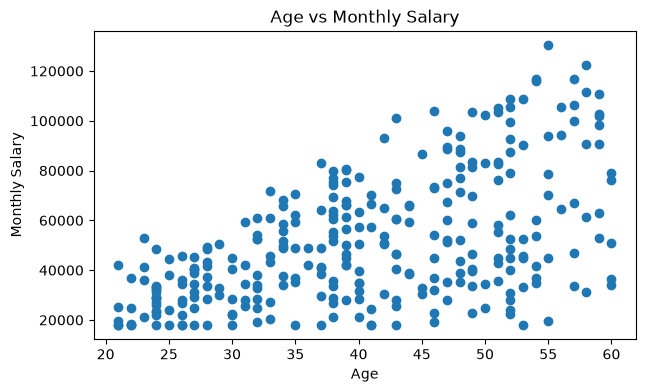

In [19]:
# Age vs Monthly Salary Analysis

import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))

plt.scatter(data['Age'], data['Monthly_Salary_INR'])

plt.title('Age vs Monthly Salary')
plt.xlabel('Age')
plt.ylabel('Monthly Salary')

plt.show()

13. Monthly Salary distribution

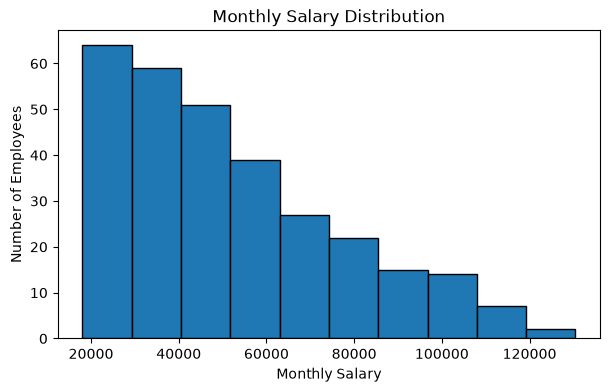

In [20]:
# Monthly Salary Distribution

plt.figure(figsize=(7, 4))

plt.hist(data['Monthly_Salary_INR'], bins=10, edgecolor='black')

plt.title("Monthly Salary Distribution")
plt.xlabel("Monthly Salary")
plt.ylabel("Number of Employees")

plt.show()

14. Salary by Dept Analysis

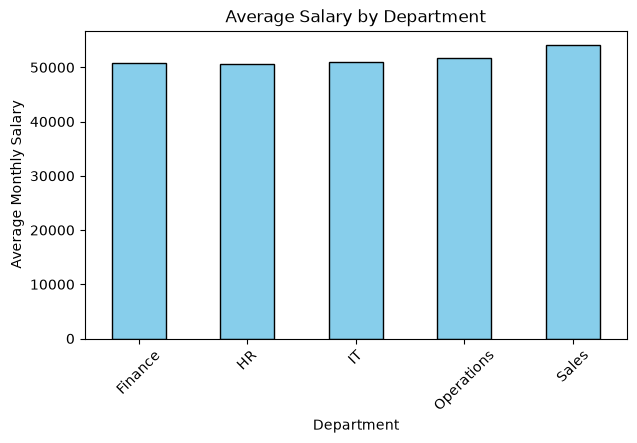

In [21]:
# Average Salary by Department

department_salary = data.groupby('Department')['Monthly_Salary_INR'].mean()

plt.figure(figsize=(7, 4))

department_salary.plot(kind='bar', color='skyblue', edgecolor='black')

plt.title("Average Salary by Department")
plt.xlabel("Department")
plt.ylabel("Average Monthly Salary")

plt.xticks(rotation=45)

plt.show()

In [22]:
print(data.columns.tolist())

['Employee_ID', 'Age', 'Years_Experience', 'Education', 'Department', 'Monthly_Salary_INR', 'Performance_Score', 'Job_Satisfaction', 'Overtime', 'Promotion_Last_2_Years', 'Attrition']


15. Years of experience vs Monthly Salary

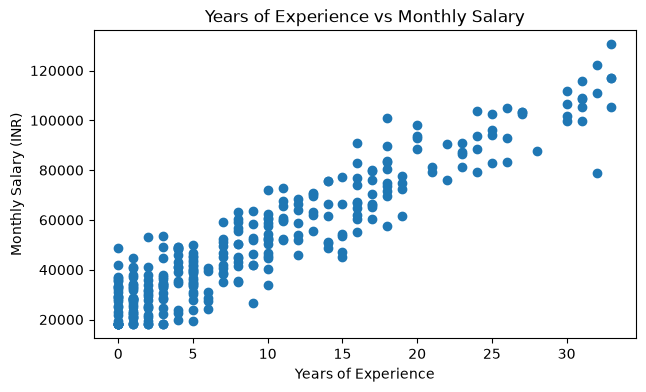

In [23]:
# Years of Experience vs Monthly Salary

plt.figure(figsize=(7, 4))

plt.scatter(data['Years_Experience'],
            data['Monthly_Salary_INR'])

plt.title("Years of Experience vs Monthly Salary")
plt.xlabel("Years of Experience")
plt.ylabel("Monthly Salary (INR)")

plt.show()

16. Job satisifaction vs Attrition

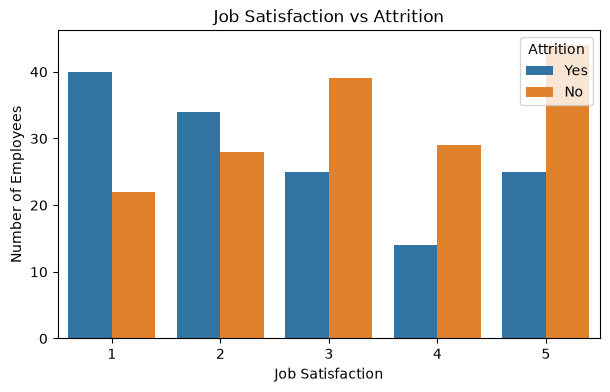

In [24]:
# Job Satisfaction vs Attrition

plt.figure(figsize=(7, 4))

sns.countplot(
    data=data,
    x='Job_Satisfaction',
    hue='Attrition'
)

plt.title("Job Satisfaction vs Attrition")
plt.xlabel("Job Satisfaction")
plt.ylabel("Number of Employees")

plt.show()

17. Overtime vs Attrition

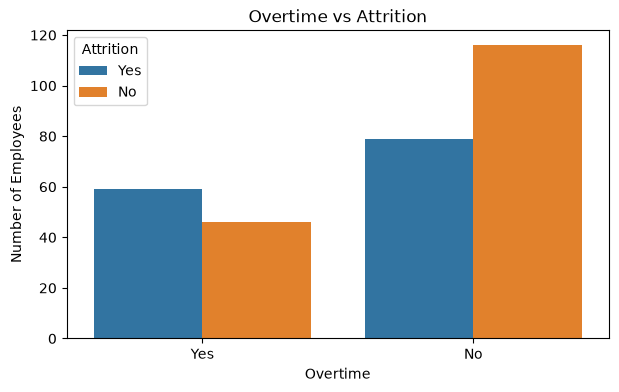

In [25]:
# Overtime vs Attrition

plt.figure(figsize=(7, 4))

sns.countplot(
    data=data,
    x='Overtime',
    hue='Attrition'
)

plt.title("Overtime vs Attrition")
plt.xlabel("Overtime")
plt.ylabel("Number of Employees")

plt.show()

18. Performance score vs Attrition

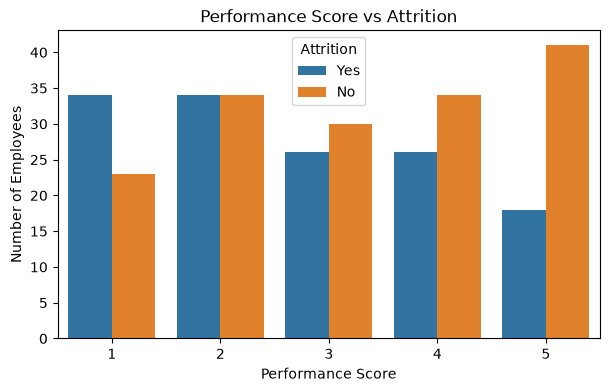

In [26]:
# Performance Score vs Attrition

plt.figure(figsize=(7, 4))

sns.countplot(
    data=data,
    x='Performance_Score',
    hue='Attrition'
)

plt.title("Performance Score vs Attrition")
plt.xlabel("Performance Score")
plt.ylabel("Number of Employees")

plt.show()

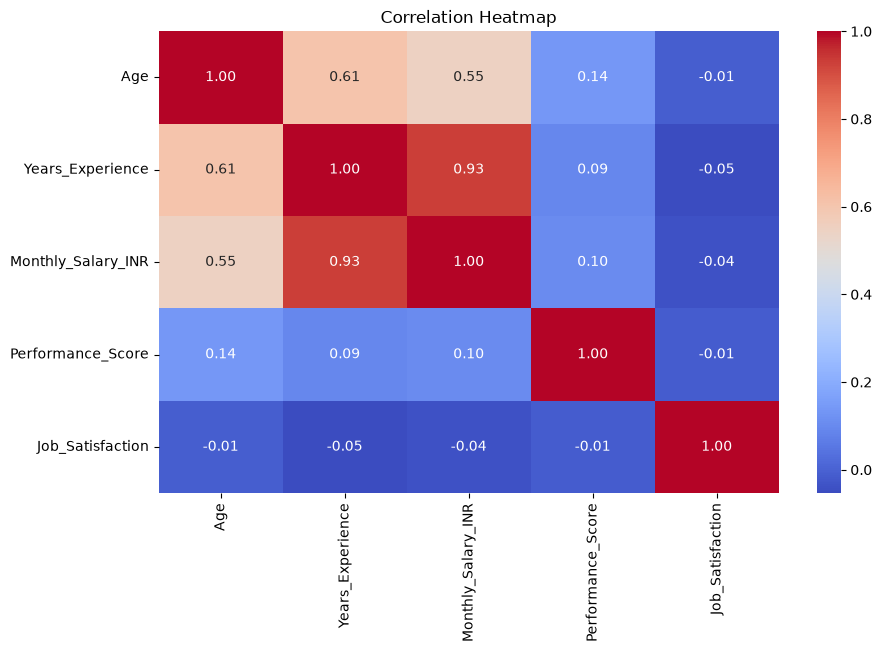

In [27]:

# Correlation Heatmap

# Select numerical columns
numeric_data = data.select_dtypes(include='number')

# Remove Employee ID because it is only an identifier
numeric_data = numeric_data.drop(
    columns=['Employee_ID'],
    errors='ignore'
)

# Calculate correlation
correlation = numeric_data.corr()

# Plot heatmap
plt.figure(figsize=(10, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap")

plt.show()


In [28]:

# Separate input features (X) and target variable (y)

X = data.drop(columns=['Attrition'])
y = data['Attrition']

print("Input Features Shape:", X.shape)
print("Target Variable Shape:", y.shape)

print("\nTarget Variable:")
print(y.head())


Input Features Shape: (300, 10)
Target Variable Shape: (300,)

Target Variable:
0    Yes
1    Yes
2    Yes
3     No
4    Yes
Name: Attrition, dtype: str


In [29]:

# Check the distribution of target variable

print("Attrition Distribution:")
print(y.value_counts())

print("\nAttrition Percentage:")
print(y.value_counts(normalize=True) * 100)


Attrition Distribution:
Attrition
No     162
Yes    138
Name: count, dtype: int64

Attrition Percentage:
Attrition
No     54.0
Yes    46.0
Name: proportion, dtype: float64


In [30]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts())

print("\nTesting Target Distribution:")
print(y_test.value_counts())


Training Data Shape: (240, 10)
Testing Data Shape: (60, 10)

Training Target Distribution:
Attrition
No     130
Yes    110
Name: count, dtype: int64

Testing Target Distribution:
Attrition
No     32
Yes    28
Name: count, dtype: int64


In [31]:
print(X.select_dtypes(include='object').columns.tolist())

['Employee_ID', 'Education', 'Department', 'Overtime', 'Promotion_Last_2_Years']


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_20440\1870110945.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(X.select_dtypes(include='object').columns.tolist())


In [32]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Remove Employee_ID from model features
X_train_model = X_train.drop(columns=['Employee_ID'])
X_test_model = X_test.drop(columns=['Employee_ID'])

# Identify categorical columns
categorical_columns = X_train_model.select_dtypes(
    include=['object', 'category']
).columns.tolist()

print("Categorical Columns:", categorical_columns)

# Apply One-Hot Encoding
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_columns)
    ],
    remainder='passthrough'
)

# Fit on training data and transform both datasets
X_train_encoded = preprocessor.fit_transform(X_train_model)
X_test_encoded = preprocessor.transform(X_test_model)

print("\nEncoded Training Shape:", X_train_encoded.shape)
print("Encoded Testing Shape:", X_test_encoded.shape)


Categorical Columns: ['Education', 'Department', 'Overtime', 'Promotion_Last_2_Years']

Encoded Training Shape: (240, 18)
Encoded Testing Shape: (60, 18)


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_20440\2601627892.py:9: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = X_train_model.select_dtypes(


In [33]:
print("Training Features:")
print(X_train.columns.tolist())

print("\nTesting Features:")
print(X_test.columns.tolist())

Training Features:
['Employee_ID', 'Age', 'Years_Experience', 'Education', 'Department', 'Monthly_Salary_INR', 'Performance_Score', 'Job_Satisfaction', 'Overtime', 'Promotion_Last_2_Years']

Testing Features:
['Employee_ID', 'Age', 'Years_Experience', 'Education', 'Department', 'Monthly_Salary_INR', 'Performance_Score', 'Job_Satisfaction', 'Overtime', 'Promotion_Last_2_Years']


In [34]:
print("Training encoded shape:", X_train_encoded.shape)
print("Testing encoded shape:", X_test_encoded.shape)

print("\nFeatures used for training:")
print(X_train_model.columns.tolist())

Training encoded shape: (240, 18)
Testing encoded shape: (60, 18)

Features used for training:
['Age', 'Years_Experience', 'Education', 'Department', 'Monthly_Salary_INR', 'Performance_Score', 'Job_Satisfaction', 'Overtime', 'Promotion_Last_2_Years']


In [35]:

# Import Logistic Regression

from sklearn.linear_model import LogisticRegression

# Create the model
lr_model = LogisticRegression(max_iter=1000)

# Train the model
lr_model.fit(X_train_encoded, y_train)

print("Logistic Regression Model Trained Successfully!")


Logistic Regression Model Trained Successfully!


c:\Users\ADMIN\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [36]:
y_pred = lr_model.predict(X_test_encoded)

print("First 10 Actual Values:")
print(y_test[:10].values)

print("\nFirst 10 Predicted Values:")
print(y_pred[:10])

First 10 Actual Values:
<StringArray>
['No', 'No', 'No', 'No', 'No', 'No', 'Yes', 'No', 'Yes', 'No']
Length: 10, dtype: str

First 10 Predicted Values:
['No' 'No' 'No' 'No' 'No' 'No' 'No' 'No' 'No' 'Yes']


In [37]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Logistic Regression Accuracy:", accuracy * 100, "%")

Logistic Regression Accuracy: 63.33333333333333 %


In [38]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

          No       0.62      0.78      0.69        32
         Yes       0.65      0.46      0.54        28

    accuracy                           0.63        60
   macro avg       0.64      0.62      0.62        60
weighted avg       0.64      0.63      0.62        60



In [39]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred, labels=['No', 'Yes'])

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[25  7]
 [15 13]]


In [40]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(random_state=42)

dt_model.fit(X_train_encoded, y_train)

print("Decision Tree Model Trained Successfully!")

Decision Tree Model Trained Successfully!


In [41]:
dt_pred = dt_model.predict(X_test_encoded)

print("First 10 Actual Values:")
print(y_test[:10].values)

print("\nFirst 10 Predicted Values:")
print(dt_pred[:10])

First 10 Actual Values:
<StringArray>
['No', 'No', 'No', 'No', 'No', 'No', 'Yes', 'No', 'Yes', 'No']
Length: 10, dtype: str

First 10 Predicted Values:
['Yes' 'Yes' 'No' 'No' 'No' 'No' 'No' 'No' 'No' 'No']


In [42]:
from sklearn.metrics import accuracy_score

dt_accuracy = accuracy_score(y_test, dt_pred)

print("Decision Tree Accuracy:", dt_accuracy * 100, "%")

Decision Tree Accuracy: 56.666666666666664 %


In [43]:
from sklearn.metrics import classification_report

print(classification_report(y_test, dt_pred))

              precision    recall  f1-score   support

          No       0.58      0.66      0.62        32
         Yes       0.54      0.46      0.50        28

    accuracy                           0.57        60
   macro avg       0.56      0.56      0.56        60
weighted avg       0.56      0.57      0.56        60



In [44]:
from sklearn.metrics import confusion_matrix

dt_cm = confusion_matrix(y_test, dt_pred, labels=['No', 'Yes'])

print("Decision Tree Confusion Matrix:")
print(dt_cm)

Decision Tree Confusion Matrix:
[[21 11]
 [15 13]]


In [45]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train_encoded, y_train)

print("Random Forest Model Trained Successfully!")

Random Forest Model Trained Successfully!


In [46]:
rf_pred = rf_model.predict(X_test_encoded)

print("First 10 Actual Values:")
print(y_test[:10].values)

print("\nFirst 10 Predicted Values:")
print(rf_pred[:10])

First 10 Actual Values:
<StringArray>
['No', 'No', 'No', 'No', 'No', 'No', 'Yes', 'No', 'Yes', 'No']
Length: 10, dtype: str

First 10 Predicted Values:
['Yes' 'No' 'No' 'No' 'Yes' 'No' 'No' 'No' 'No' 'Yes']


In [47]:
from sklearn.metrics import accuracy_score

rf_accuracy = accuracy_score(y_test, rf_pred)

print("Random Forest Accuracy:", rf_accuracy * 100, "%")

Random Forest Accuracy: 56.666666666666664 %


In [48]:
from sklearn.metrics import classification_report

print(classification_report(y_test, rf_pred))

              precision    recall  f1-score   support

          No       0.57      0.75      0.65        32
         Yes       0.56      0.36      0.43        28

    accuracy                           0.57        60
   macro avg       0.56      0.55      0.54        60
weighted avg       0.56      0.57      0.55        60



In [49]:
from sklearn.metrics import confusion_matrix

rf_cm = confusion_matrix(y_test, rf_pred, labels=['No', 'Yes'])

print("Random Forest Confusion Matrix:")
print(rf_cm)

Random Forest Confusion Matrix:
[[24  8]
 [18 10]]


In [50]:
import pandas as pd

model_comparison = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Decision Tree',
        'Random Forest'
    ],
    'Accuracy (%)': [
        dt_accuracy * 100,
        dt_accuracy * 100,
        rf_accuracy * 100
    ]
})

print(model_comparison)

                 Model  Accuracy (%)
0  Logistic Regression     56.666667
1        Decision Tree     56.666667
2        Random Forest     56.666667


In [52]:
from sklearn.metrics import accuracy_score

dt_accuracy = accuracy_score(y_test, y_pred)
dt_accuracy = accuracy_score(y_test, dt_pred)
rf_accuracy = accuracy_score(y_test, rf_pred)

model_comparison = pd.DataFrame({
    'Model': ['Logistic Regression', 'Decision Tree', 'Random Forest'],
    'Accuracy (%)': [
        dt_accuracy * 100,
        dt_accuracy * 100,
        rf_accuracy * 100
    ]
})

print(model_comparison)

                 Model  Accuracy (%)
0  Logistic Regression     56.666667
1        Decision Tree     56.666667
2        Random Forest     56.666667


In [53]:
print("Logistic Regression:", accuracy_score(y_test, y_pred))
print("Decision Tree:", accuracy_score(y_test, dt_pred))
print("Random Forest:", accuracy_score(y_test, rf_pred))

Logistic Regression: 0.6333333333333333
Decision Tree: 0.5666666666666667
Random Forest: 0.5666666666666667


In [54]:
import joblib

joblib.dump(lr_model, 'best_attrition_model.pkl')
joblib.dump(preprocessor, 'attrition_preprocessor.pkl')

print("Best model saved successfully!")
print("Preprocessor saved successfully!")

Best model saved successfully!
Preprocessor saved successfully!


In [55]:
import os

print("Model file exists:", os.path.exists('best_attrition_model.pkl'))
print("Preprocessor file exists:", os.path.exists('attrition_preprocessor.pkl'))

Model file exists: True
Preprocessor file exists: True


In [56]:
loaded_model = joblib.load('best_attrition_model.pkl')
loaded_preprocessor = joblib.load('attrition_preprocessor.pkl')

print("Saved model loaded successfully!")
print("Saved preprocessor loaded successfully!")

Saved model loaded successfully!
Saved preprocessor loaded successfully!


In [57]:
loaded_X_test = loaded_preprocessor.transform(X_test_model)

loaded_predictions = loaded_model.predict(loaded_X_test)

print("Original Model Predictions:")
print(y_pred[:10])

print("\nLoaded Model Predictions:")
print(loaded_predictions[:10])

print("\nPredictions Match:",
      (y_pred == loaded_predictions).all())

Original Model Predictions:
['No' 'No' 'No' 'No' 'No' 'No' 'No' 'No' 'No' 'Yes']

Loaded Model Predictions:
['No' 'No' 'No' 'No' 'No' 'No' 'No' 'No' 'No' 'Yes']

Predictions Match: True
